# Assignment 1
**Credits**: Federico Ruggeri, Giulia Grundler, Paolo Torroni

**Keywords**: Unfair Clause Detection, Multi-label Classification, RNNs, Transformers, Huggingface

<style>
/* Long code lines wrap instead of running off the right edge of the slide,
   and a slide taller than the 700px deck scrolls instead of being cut. */
.reveal .jp-RenderedHTMLCommon pre,
.reveal .highlight pre,
.reveal pre, .reveal pre code {
  white-space: pre-wrap;
  word-break: break-word;
  box-sizing: border-box;
  max-width: 100%;
}
.reveal .slides section:not(.stack) {
  max-height: 700px;
  overflow-y: auto;
  overflow-x: hidden;
}
</style>

# Contact
For any doubt, question, issue or help, you can always contact us at the following email addresses:

Teaching Assistants:

- Federico Ruggeri -> federico.ruggeri6@unibo.it
- Giulia Grundler -> giulia.grundler2@unibo.it

# Introduction

You are asked to address **unfair clause detection** in online Terms of Service (ToS), following the
[CLAUDETTE](http://claudette.eui.eu/) line of work.

Consumer contracts are long, nobody reads them, and some of their clauses are *potentially unfair*: they grant the
service provider rights that a consumer-protection authority would likely consider abusive. The task is to read one
clause at a time and flag which kinds of unfairness it carries.

## Problem Definition

Given the text of a single contract clause, predict which of the following five unfairness categories apply:

| Label | Category | Meaning |
|-------|----------|---------|
| `A`   | Arbitration | Disputes must go to arbitration instead of a court. |
| `CH`  | Unilateral change | The provider may change the contract or the service unilaterally. |
| `CR`  | Content removal | The provider may remove or block user content at its own discretion. |
| `LTD` | Limitation of liability | The provider limits or excludes its liability towards the consumer. |
| `TER` | Unilateral termination | The provider may terminate the contract or the user account at its own discretion. |

### Multi-label, not multi-class

This is a **multi-label** problem, **not** multi-class:

* a clause may carry **none** of the five categories (the large majority of clauses);
* a clause may carry **more than one** category at the same time.

Each category is therefore an independent binary decision, and your model has **five** outputs.

### Examples

#### A - Arbitration

''*the arbitrator has exclusive authority to resolve any dispute relating to the interpretation , applicability , or
enforceability of this binding arbitration agreement .*''

#### CH - Unilateral change

''*we reserve the right to modify any provision hereof from time to time , in our sole discretion , and such
modification shall be effective immediately upon its posting on the website .*''

### Examples (continued)

#### CR - Content removal

''*we will not edit or monitor user-provided content , but we reserve the right to remove any user provided content
which comes to our attention and which , in our sole discretion , breaches this agreement .*''

#### LTD - Limitation of liability

''*the collective liability of mozilla and the indemnified parties under this agreement will not exceed $ 500 -lrb-
five hundred dollars -rrb- .*''

### Examples (continued)

#### TER - Unilateral termination

''*in case of a dispute with the member who owns the site , we are allowed to ban this member and remove him/her from
the service at our discretion .*''

#### Multiple labels on the same clause

''*we may remove your dna results and/or dna reports and/or terminate your membership at any time , without notice .*''
$\rightarrow$ `CR` **and** `TER`.

''*we reserve the right to modify or terminate the service or your access to the service for any reason , without
notice , at any time , and without liability to you .*'' $\rightarrow$ `CH` **and** `TER`.

#### No label (fair clause)

''*this dispute resolution provision will be governed by the federal arbitration act .*''

Note how close this last clause is to the `A` example: the topic is arbitration, but the clause does not impose it.
**Topic is not the label.**

# [Task 1 - 0.25 points] Corpus

We use **ToS-100**: 100 Terms of Service documents split into 20,417 clauses, each annotated with the five
unfairness categories above.

The dataset is available on Zenodo: **[ToS-100](https://doi.org/10.5281/zenodo.22691656)**

The archive contains three `.csv` files: `train.csv`, `validation.csv` and `test.csv`.

### Dataset Description

* Clauses come from real Terms of Service of online platforms (Mozilla, Netflix, Spotify, ...).
* The text is already **lowercased** and **tokenized** in Penn Treebank style: brackets appear as `-lrb-` / `-rrb-`,
  quotes as `` `` `` and `''`, and clitics are detached (`mozilla 's`, `do n't`).
* Splits are **by document**, not by clause: all clauses of one contract stay in the same split. Contracts copy each
  other almost verbatim, so a clause-level split would leak the test set into training.

### Splits

| Split | Documents | Clauses | A | CH | CR | LTD | TER |
|-------|-----------|---------|---|----|----|-----|-----|
| train | 80 | 15,837 | 75 | 268 | 165 | 504 | 318 |
| validation | 10 | 2,548 | 20 | 43 | 32 | 75 | 59 |
| test | 10 | 2,032 | 11 | 33 | 19 | 47 | 43 |

The corpus is **heavily imbalanced**: 18,843 clauses out of 20,417 (92.3%) carry no label at all.

### Example

| column | value |
|--------|-------|
| `document_ID` | `1` |
| `document` | `MyHeritage` |
| `text` | `we may remove your dna results and/or dna reports and/or terminate your membership at any time , without notice .` |
| `A` | `0` |
| `CH` | `0` |
| `CR` | `1` |
| `LTD` | `0` |
| `TER` | `1` |

The `*_targets` columns in the original release point to a knowledge base of legal rationales. **They are not used in
this assignment** and can be dropped.

### Instructions

1. **Download** the dataset from Zenodo.
2. **Load** the three CSV files and encode them as `pandas.DataFrame`.
3. **Remove unwanted columns**: keep only `document_ID`, `text`, and the five label columns `A`, `CH`, `CR`, `LTD`,
   `TER`.
4. **Build the target**: for each clause, a 5-dimensional binary vector `[A, CH, CR, LTD, TER]`.
5. **Report** basic statistics of each split: number of clauses, number of positives per category, number of clauses
   with 0 / 1 / 2+ labels.

**Note**: do **not** re-split the data. The provided splits are document-based on purpose.

In [2]:
# NOTE: torch/transformers must be imported BEFORE tensorflow, otherwise the kernel crashes
# (LLVM "CommandLine Error: Option ... registered more than once")
import torch
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)
import tensorflow as tf
from dataclasses import dataclass, fields
import itertools
import gensim.downloader as api
import pandas as pd
import nltk
from nltk.stem import WordNetLemmatizer
import numpy as np
import math
import matplotlib.pyplot as plt
import re
from collections.abc import Callable
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from types import SimpleNamespace
from typing import Literal


LABELS = ["A", "CH", "CR", "LTD", "TER"]


/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1794263515.493714   92792 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
def download_split(split: str):
    url = f"https://zenodo.org/api/records/22691656/files/{split}.csv/content"

    df = pd.read_csv(url)[["document_ID", "text"] + LABELS]
    y = df[LABELS].astype(int).values
    n = y.sum(axis=1)
    
    print(f"\n== {split} ==")
    print("clauses:", len(df))
    print("positives:")
    for label, count in zip(LABELS, y.sum(axis=0)):
        print(f"  {label}: {count}")
    print("labels per clause: 0 =", (n == 0).sum(), "| 1 =", (n == 1).sum(), "| 2+ =", (n >= 2).sum())

    return df

In [4]:
train = download_split('train')
validation = download_split('validation')
test = download_split('test')


== train ==
clauses: 15837
positives:
  A: 75
  CH: 268
  CR: 165
  LTD: 504
  TER: 318
labels per clause: 0 = 14614 | 1 = 1124 | 2+ = 99

== validation ==
clauses: 2548
positives:
  A: 20
  CH: 43
  CR: 32
  LTD: 75
  TER: 59
labels per clause: 0 = 2336 | 1 = 195 | 2+ = 17

== test ==
clauses: 2032
positives:
  A: 11
  CH: 33
  CR: 19
  LTD: 47
  TER: 43
labels per clause: 0 = 1893 | 1 = 127 | 2+ = 12


# [Task 2 - 0.25 points] Data Cleaning and Label Analysis

This task has two halves, which weigh the same:

* **Task 2a**: clean the text of the corpus.
* **Task 2b**: measure how imbalanced the labels are, and decide what to do about it.

### [Task 2a] Data Cleaning

The text is legal prose that has already gone through a tokenizer, which leaves artifacts behind.

#### Instructions

* **Restore bracket tokens**: `-lrb-` $\rightarrow$ `(`, `-rrb-` $\rightarrow$ `)`, and likewise `-lsb-` / `-rsb-`.
* **Normalize quote tokens** (`` `` ``, `''`, `` ` ``, `'`).
* **Reattach clitics** or remove them (`mozilla 's` $\rightarrow$ `mozilla's`, `do n't` $\rightarrow$ `don't`).
* **Remove clause numbering and bullets** (e.g. `1.`, `2.3.1`, `a )`, `-`) at the beginning of a clause.
* **Normalize whitespace** and remove leftover special characters.
* **Perform lemmatization** to reduce words to their base form.

#### Warning

Be careful with what you remove.

Modal verbs (`may`, `shall`, `will`), negations and pronouns (`we`, `you`) carry most of the signal in this task, so
an aggressive stopword list can hurt you.

Justify your choices.

In [4]:


def lemmatize(text: str) -> str:
    nltk.download("wordnet", quiet=True)
    lemmatizer = WordNetLemmatizer()

    return re.sub(
        r"[a-z]+",
        lambda m: lemmatizer.lemmatize(lemmatizer.lemmatize(m.group(), "v"), "n"),
        text,
    )


def clean_text(text: str) -> str:
    bracket_mappings = {"-lrb-": "(", "-rrb-": ")", "-lsb-": "[", "-rsb-": "]"}
    clitics = r"\s+('s|'re|'ve|'ll|'d|'m|n't)\b"
    numbering = r"^\s*(\d+(\.\d+)*\.?\s|\(?\s*[a-z]\s*\)|[-•*]+)\s*"

    text = text.lower()
    for token, char in bracket_mappings.items():
        text = text.replace(token, char)
    text = text.replace("``", '"').replace("''", '"').replace("`", "'")
    text = re.sub(clitics, r"\1", text)
    text = re.sub(numbering, "", text)
    text = re.sub(r"[^\w\s.,;:!?()\[\]'\"/%$&-]", " ", text)  # leftover special chars
    text = re.sub(r"\s+", " ", text).strip()
    # text = lemmatize(text)
    return text


def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["text"] = df["text"].map(clean_text)
    return df


In [5]:
train = preprocess(train)
validation = preprocess(validation)
test = preprocess(test)

train["text"].str.split().str.len().describe(percentiles=[.9, .95, .99])


count    15837.000000
mean        32.004862
std         24.931253
min          3.000000
90%         58.000000
95%         75.000000
99%        132.640000
max        353.000000
Name: text, dtype: float64

### [Task 2b] Label Analysis

#### Instructions

* Compute the **positive rate** of each of the five categories on the training set.
* Compute and comment the **co-occurrence** between categories (e.g. a 5x5 matrix of joint counts).
* Given the imbalance, **choose and justify** a mitigation strategy for training.
* You will apply the chosen strategy in Task 5.

#### Mitigation strategies

Some options, none of them mandatory:

* per-class positive weighting in the loss (`pos_weight` in `BCEWithLogitsLoss`);
* resampling of positive clauses;
* no mitigation, with threshold tuning at inference time instead.

In [6]:
def label_analysis(train: pd.DataFrame) -> tuple[pd.Series, pd.DataFrame]:
    y = train[LABELS].astype(int)
    rates = y.mean().rename("positive_rate")
    cooc = y.T @ y
    return rates, cooc


def plot_rates(rates: pd.Series) -> None:
    fig, ax = plt.subplots()
    bars = ax.bar(rates.index, rates * 100)
    ax.bar_label(bars, fmt="%.2f%%")
    ax.set_ylabel("Positive rate (%)")
    ax.set_title("Positive rate per label (train)")
    plt.show()


def plot_cooccurrence(cooc: pd.DataFrame) -> None:
    fig, ax = plt.subplots()
    im = ax.imshow(cooc.values, cmap="Blues")
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, cooc.iloc[i, j], ha="center", va="center")
    fig.colorbar(im)
    ax.set_title("Label co-occurrence (train)")
    plt.show()

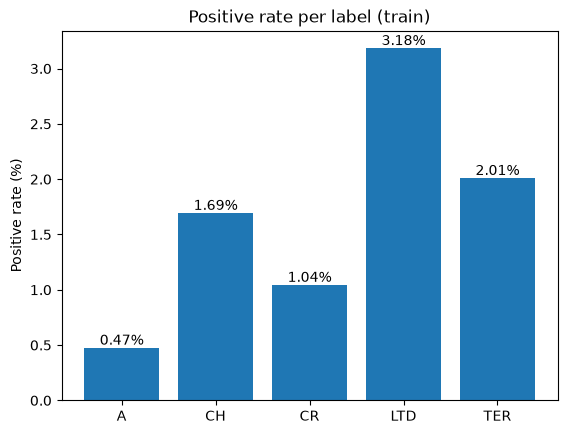

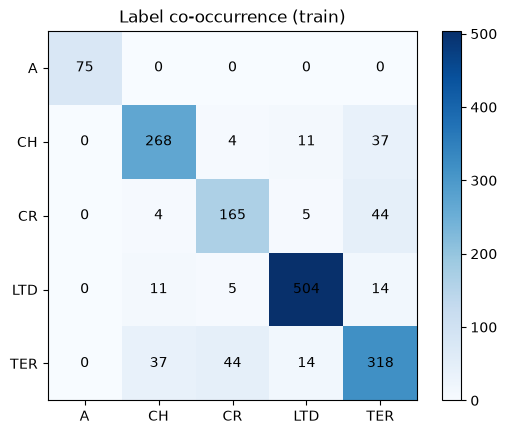

In [7]:
rates, cooc = label_analysis(train)
plot_rates(rates)
plot_cooccurrence(cooc)

# [Task 3 - 0.25 points] Text Encoding

To train a neural unfair-clause classifier, you first need to encode text into numerical format.

### Instructions

* Embed words using **GloVe embeddings**.
* You are **free** to pick any embedding dimension.

### What about OOV tokens?

* All the tokens in the **training** set that are not in GloVe **must** be added to the vocabulary.
* For the remaining tokens (i.e., OOV in the validation and test sets), you have to assign them a **special token**
  (e.g., `<UNK>`) and a **static** embedding.
* You are **free** to define the static embedding using any strategy (e.g., random, neighbourhood, etc...)

**Note**: legal text has its own vocabulary (`hereof`, `indemnify`, `arbitrator`), so expect a non-trivial OOV rate.
Report it.

### More about OOV

For a given token:

* **If in train set**: add to vocabulary and assign an embedding (use GloVe if token in GloVe, custom embedding
  otherwise).
* **If in val/test set**: assign special token if not in vocabulary and assign custom embedding.

Your vocabulary **should**:

* Contain all tokens in train set; or
* Union of tokens in train set and in GloVe $\rightarrow$ we make use of existing knowledge!

In [8]:
DIM = 100
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"


# NOTE: it now only contains tokens from the train set, but not GloVe \ train
def build_embedding(train, dim, seed=0):
    glove = api.load(f"glove-wiki-gigaword-{dim}")
    rng = np.random.default_rng(seed)

    tokens = sorted({w for text in train["text"] for w in text.split()})
    word2idx = {w: i for i, w in enumerate([PAD_TOKEN, UNK_TOKEN] + tokens)}
    emb = np.zeros((len(word2idx), dim), dtype="float32")

    for w, i in word2idx.items():
        # padding token stays at 0
        if w == PAD_TOKEN:
            continue
        # <UNK> gets the average of all glove embeddings
        elif w == UNK_TOKEN:
            emb[i] = glove.vectors.mean(axis=0)
        # if in glove use that
        elif w in glove:
            emb[i] = glove[w]
        # unknowns from `train` initialized with a gaussian
        else:
            emb[i] = rng.normal(0, 0.1, dim)

    return word2idx, emb


def to_xy(df, word2idx, sequence_len):
    """Texts -> padded id matrix (0 = <PAD>), labels -> (n, 5) array."""

    ids = [
        [word2idx.get(t, word2idx[UNK_TOKEN]) for t in text.split()]
        for text in df["text"]
    ]
    x = tf.keras.utils.pad_sequences(
        ids,
        maxlen=sequence_len,
        padding="post",
        truncating="post",
        value=word2idx[PAD_TOKEN],
    )
    return x, df[LABELS].values.astype("float32")



word2idx, emb = build_embedding(train, DIM)
UNK_ID = word2idx[UNK_TOKEN]
PAD_ID = word2idx[PAD_TOKEN]


# [Task 4 - 0.25 points] Model definition

You are now tasked to define your unfair clause classifier.

### Instructions

* **Baseline**: implement a Bidirectional LSTM with a Dense layer on top.

* **Stacked**: add an additional Bidirectional LSTM layer to the Baseline model.

**Note**: You are **free** to experiment with hyper-parameters.

### Token to embedding mapping

You can follow two approaches for encoding tokens in your classifier.

### Work directly with embeddings

- Compute the embedding of each input token
- Feed the mini-batches of shape ``(batch_size, # tokens, embedding_dim)`` to your model

### Work with Embedding layer

- Encode input tokens to token ids
- Define a Embedding layer as the first layer of your model
- Compute the embedding matrix of all known tokens (i.e., tokens in your vocabulary)
- Initialize the Embedding layer with the computed embedding matrix
- You are **free** to set the Embedding layer trainable or not

In [9]:
def build_lstm(
    emb,
    state_dim=64,
    dropout=0.3,
    loss="binary_crossentropy",
    optimizer="adam",
    stacked=False,
):
    model = tf.keras.Sequential([
        # trainable embedding matrix, seeded with GloVe's embedding
        tf.keras.layers.Embedding(
            input_dim=emb.shape[0],
            output_dim=emb.shape[1],
            weights=[emb],
            mask_zero=True,
            name='encoder_embedding'
        ),
        # optional "second" LSTM layer for the stacked variant
        *(
            [tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(state_dim, return_sequences=True))] 
            if stacked else []
        ),
        # bidirectional LSTM
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(state_dim)),
        tf.keras.layers.Dropout(dropout),
        # one single FC layer
        tf.keras.layers.Dense(len(LABELS), activation="sigmoid"),
    ])
    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=[tf.keras.metrics.AUC(multi_label=True, name="auc")]
    )

    return model


def weighted_bce(pos_weight):
    pw = tf.constant(pos_weight, dtype="float32")

    def weighted_bce_loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce = -(pw * y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
        return tf.reduce_mean(bce, axis=-1)  # mean over the 5 labels -> per-sample loss

    return weighted_bce_loss


# TODO move this somewhere else
y = train[LABELS].astype(int)
rates = y.mean().rename("positive_rate")
pos_weight = np.sqrt((1 - rates) / rates)  # softened neg/pos ratio
weighted_loss = weighted_bce(pos_weight)

W0000 00:00:1793901412.466707  379467 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [10]:
# embedding = tf.keras.layers.Embedding(
#     input_dim=vocab_size,
#     output_dim=embedding_dimension,
#     weights=[embedding_matrix],
#     mask_zero=True,                   # automatically masks padding tokens
#     name='encoder_embedding'
# )


# [Task 5 - 0.5 points] Training and Evaluation

You are now tasked to train and evaluate the Baseline and Stacked models.

### Instructions

* Pick **at least** three seeds for robust estimation.
* Train **all** models on the train set, applying the imbalance strategy chosen in Task 2b.
* Evaluate **all** models on the validation and test sets.
* Compute **macro** F1-score, precision, and recall over the five categories on the validation set.
* Also report the **per-category** F1-score: the macro average hides the fact that `A` has 75 positive training
  clauses and `LTD` has 504.
* Report average and standard deviation measures over seeds for each metric.
* Pick the **best** performing model according to the observed validation set performance (use macro F1-score).

### Which metric, and which not

Macro F1 here is the average of the five **binary** F1-scores, one per category, each computed on the positive class.

Accuracy is meaningless on this corpus: a model predicting all zeros scores above 92%. **Do not** report it as your
main metric.

In [5]:
# anything Keras accepts as `loss`: a name ("binary_crossentropy"), a Loss object, or a function (y_true, y_pred) -> loss
LossFn = str | tf.keras.losses.Loss | Callable[[tf.Tensor, tf.Tensor], tf.Tensor]


@dataclass
class LstmConfig:
    batch_size: int
    lr: float
    loss: LossFn
    weight_decay: float = 0.0
    dropout: float = 0.0
    mask_prob: float = 0.0
    epochs: int = 15
    sequence_len: int = 100
    schedule: Literal[None, "reduce", "cosine"] = None



def build_optimizer(config: LstmConfig, x_tr):
    steps_per_epoch = math.ceil(len(x_tr) / config.batch_size)
    total_steps = config.epochs * steps_per_epoch
    warmup_steps = int(0.1 * total_steps)

    schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0,                 # lr at step 0: where the warmup starts
        decay_steps=total_steps - warmup_steps,    # length of the cosine part
        alpha=0.0,                                 # final lr as a fraction of the peak
        warmup_target=config.lr,                   # peak lr, reached after the warmup
        warmup_steps=warmup_steps,                 # e.g. 1-2 epochs worth of steps
    )
    return tf.keras.optimizers.AdamW(
        learning_rate=schedule if config.schedule=="cosine" else config.lr,
        weight_decay=config.weight_decay
    )


def train_lstm(config: LstmConfig):
    x_tr, y_tr = to_xy(train, word2idx, config.sequence_len)
    x_val, y_val = to_xy(validation, word2idx, config.sequence_len)
    model = build_lstm(
        emb,
        dropout=config.dropout,
        loss=config.loss,
        optimizer=build_optimizer(config, x_tr),
    )

    UNK_ID = word2idx[UNK_TOKEN]
    def mask_tokens(x, y):
        drop = (tf.random.uniform(tf.shape(x)) < config.mask_prob) & (x != PAD_ID)   # never mask padding
        return tf.where(drop, UNK_ID, x), y

    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_tr, y_tr))
        .shuffle(len(x_tr))
        .batch(config.batch_size)
        .map(mask_tokens)
    )
    history = model.fit(
        train_ds,
        validation_data=(x_val, y_val),
        epochs=config.epochs,
        batch_size=config.batch_size,
        callbacks=[
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
        ] if config.schedule == "reduce" else []
    )

    return model, history


def per_label_metrics(y_true, prob, threshold=0.5):
    """Per-label accuracy / precision / recall / F1 from predicted probabilities (shared by LSTM and BERT)."""
    pred = (prob > threshold).astype(int)
    return {
        "accuracy": [accuracy_score(y_true[:, i], pred[:, i]) for i in range(len(LABELS))],
        "precision": precision_score(y_true, pred, average=None, zero_division=0),
        "recall": recall_score(y_true, pred, average=None, zero_division=0),
        "F1": f1_score(y_true, pred, average=None, zero_division=0),
    }


def test_metrics(model, x_test, y_test):
    test_loss, test_auc = model.evaluate(x_test, y_test, verbose=0)
    print(f"test loss: {test_loss:.4f} | test AUC: {test_auc:.4f}")

    prob = model.predict(x_test)
    return {"loss": test_loss, "auc": test_auc, **per_label_metrics(y_test, prob)}


def plot_lstm_results(history, metrics):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, m in zip(axes, ["loss", "auc"]):
        if m in history.history:  # e.g. the BERT run has no train AUC
            ax.plot(history.history[m], label="train")
        ax.plot(history.history[f"val_{m}"], label="val")
        ax.set_xlabel("epoch"); ax.set_title(m); ax.legend()
    plt.show()

    test_loss, test_auc = metrics['loss'], metrics['auc']
    print(f"test loss: {test_loss:.4f} | test AUC: {test_auc:.4f}")

    metrics = {
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "F1": metrics["F1"],
    }
    x = np.arange(len(LABELS))
    width = 0.2
    fig, ax = plt.subplots(figsize=(10, 4))
    for k, (name, values) in enumerate(metrics.items()):
        bars = ax.bar(x + (k - 1.5) * width, values, width, label=f"{name} (macro = {np.mean(values):.3f})")
        ax.bar_label(bars, fmt="%.2f", fontsize=7)
    ax.set_xticks(x, LABELS)
    ax.set_ylim(0, 1.1)
    ax.set_title("Test metrics per label")
    ax.legend()
    plt.show()



##### Hyper-parameter sweep

In [12]:
def product_configs(
    batch_size: list[int],
    lr: list[float],
    loss: list[LossFn],
    weight_decay: list[float] = [],
    dropout: list[float] = [],
    mask_prob: list[float] = [],
    epochs: list[int] = [],
    sequence_len: list[int] = [],
    schedule: list = [],
) -> list[LstmConfig]:
    grid = {
        "batch_size": batch_size,
        "lr": lr,
        "loss": loss,
        "weight_decay": weight_decay,
        "dropout": dropout,
        "mask_prob": mask_prob,
        "epochs": epochs,
        "sequence_len": sequence_len,
        "schedule": schedule,
    }
    grid = {
        name: values
        for name, values in grid.items() 
        if values # prune empty lists
    }
    return [LstmConfig(**dict(zip(grid, combo))) for combo in itertools.product(*grid.values())]


def _fmt(value) -> str:
    """Readable name for a hyper-parameter value (functions are shown by name)."""
    return value if isinstance(value, str) else getattr(value, "__name__", str(value))


def run_score(history, metrics, metric: str) -> float:
    """Scalar score of a run: `val_*` metrics are the last-epoch value from the history,
    anything else is a key of `test_metrics` (per-label arrays are macro-averaged)."""
    if metric.startswith("val_"):
        return float(history.history[metric][-1])
    return float(np.mean(metrics[metric]))


def plot_sweep(configs, results, metric="val_auc", top_k=5):
    """results[i] = (history, metrics) of configs[i]."""
    scores = [run_score(h, m, metric) for h, m in results]
    names = [f.name for f in fields(LstmConfig)]
    values = {n: list(dict.fromkeys(getattr(c, n) for c in configs)) for n in names}
    varying = [n for n in names if len(values[n]) > 1]

    # 1) metric trend per hyper-parameter, averaged over all the runs sharing a value
    if varying:
        fig, axes = plt.subplots(1, len(varying), figsize=(4 * len(varying), 3.5), sharey=True, squeeze=False)
        for ax, n in zip(axes[0], varying):
            means = [np.mean([s for s, c in zip(scores, configs) if getattr(c, n) == v]) for v in values[n]]
            ax.plot(range(len(means)), means, marker="o")
            ax.set_xticks(range(len(means)), [_fmt(v) for v in values[n]])
            ax.set_xlabel(n)
        axes[0][0].set_ylabel(metric)
        fig.suptitle(f"{metric}, averaged over runs sharing each value")
        fig.tight_layout()
        plt.show()

    # 2) train curves of the top_k runs (lower is better for losses, higher otherwise)
    order = np.argsort(scores)
    best = order[:top_k] if "loss" in metric else order[::-1][:top_k]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
    for ax, key in zip(axes, ["auc", "loss"]):
        for i in best:
            label = f"{scores[i]:.3f} | " + ", ".join(f"{n}={_fmt(getattr(configs[i], n))}" for n in varying)
            ax.plot(results[i][0].history[key], label=label)
        ax.set_title(f"train {key} - top {top_k} by {metric}")
        ax.set_xlabel("epoch")
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    plt.show()


In [13]:
x_te, y_te = to_xy(test, word2idx, 100)

configs = product_configs(
    dropout=[0.0, 0.2, 0.4],
    batch_size=[64, 128, 256],
    lr=[1e-3],
    weight_decay=[0.0, 1e-2],
    mask_prob=[0.1, 0.2, 0.3],
    loss=[weighted_loss],
    schedule=[None, 'cosine', 'reduce'],
)
print(f"Sweeping over {len(configs)} hyper-parameter combinations")

results = []
for c in configs:
    model, history = train_lstm(c)
    metrics = test_metrics(model, x_te, y_te)
    results.append((history, metrics))


Sweeping over 162 hyper-parameter combinations
Epoch 1/15


/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


248/248 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - auc: 0.7698 - loss: 0.3232 - val_auc: 0.9166 - val_loss: 0.2840
Epoch 2/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9583 - loss: 0.1659 - val_auc: 0.9479 - val_loss: 0.1895
Epoch 3/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 14s 55ms/step - auc: 0.9804 - loss: 0.1167 - val_auc: 0.9558 - val_loss: 0.1749
Epoch 4/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 14s 55ms/step - auc: 0.9880 - loss: 0.0963 - val_auc: 0.9522 - val_loss: 0.1782
Epoch 5/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step - auc: 0.9915 - loss: 0.0761 - val_auc: 0.9508 - val_loss: 0.1758
Epoch 6/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - auc: 0.9951 - loss: 0.0618 - val_auc: 0.9558 - val_loss: 0.1804
Epoch 7/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - auc: 0.9965 - loss: 0.0515 - val_auc: 0.9524 - val_loss: 0.2036
Epoch 8/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - auc: 0.9973 - loss: 0.0440 - val_auc: 0.9490 - val_loss: 0.2081
Epoch 9/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/st

/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


248/248 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - auc: 0.5740 - loss: 0.4439 - val_auc: 0.8701 - val_loss: 0.3435
Epoch 2/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - auc: 0.9143 - loss: 0.2230 - val_auc: 0.9320 - val_loss: 0.2200
Epoch 3/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9709 - loss: 0.1386 - val_auc: 0.9546 - val_loss: 0.1793
Epoch 4/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9856 - loss: 0.1007 - val_auc: 0.9526 - val_loss: 0.1838
Epoch 5/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - auc: 0.9903 - loss: 0.0810 - val_auc: 0.9572 - val_loss: 0.1659
Epoch 6/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9944 - loss: 0.0638 - val_auc: 0.9464 - val_loss: 0.2061
Epoch 7/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9958 - loss: 0.0552 - val_auc: 0.9514 - val_loss: 0.2030
Epoch 8/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9972 - loss: 0.0443 - val_auc: 0.9593 - val_loss: 0.1858
Epoch 9/15
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/st

/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (315 outputs left out)

/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - auc: 0.5062 - loss: 0.5445 - val_auc: 0.5778 - val_loss: 0.4473
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.6182 - loss: 0.3724 - val_auc: 0.8565 - val_loss: 0.3566
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.8578 - loss: 0.2663 - val_auc: 0.9161 - val_loss: 0.2621
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9307 - loss: 0.2029 - val_auc: 0.9395 - val_loss: 0.2140
Epoch 5/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9593 - loss: 0.1669 - val_auc: 0.9434 - val_loss: 0.2007
Epoch 6/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9613 - loss: 0.1557 - val_auc: 0.9535 - val_loss: 0.1811
Epoch 7/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9695 - loss: 0.1377 - val_auc: 0.9482 - val_loss: 0.1932
Epoch 8/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 129ms/step - auc: 0.9760 - loss: 0.1284 - val_auc: 0.9513 - val_loss: 0.1822
Epoch 9/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9779 

/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - auc: 0.5273 - loss: 0.4291 - val_auc: 0.7656 - val_loss: 0.4025 - learning_rate: 0.0010
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.7572 - loss: 0.3243 - val_auc: 0.8848 - val_loss: 0.3004 - learning_rate: 0.0010
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9080 - loss: 0.2268 - val_auc: 0.9309 - val_loss: 0.2240 - learning_rate: 0.0010
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 129ms/step - auc: 0.9401 - loss: 0.1887 - val_auc: 0.9439 - val_loss: 0.1944 - learning_rate: 0.0010
Epoch 5/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9528 - loss: 0.1653 - val_auc: 0.9459 - val_loss: 0.2030 - learning_rate: 0.0010
Epoch 6/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9658 - loss: 0.1411 - val_auc: 0.9499 - val_loss: 0.1987 - learning_rate: 0.0010
Epoch 7/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step - auc: 0.9775 - loss: 0.1209 - val_auc: 0.9484 - val_loss: 0.1912 - learning_rate: 5.0000e-04
Epoch 8/15
6

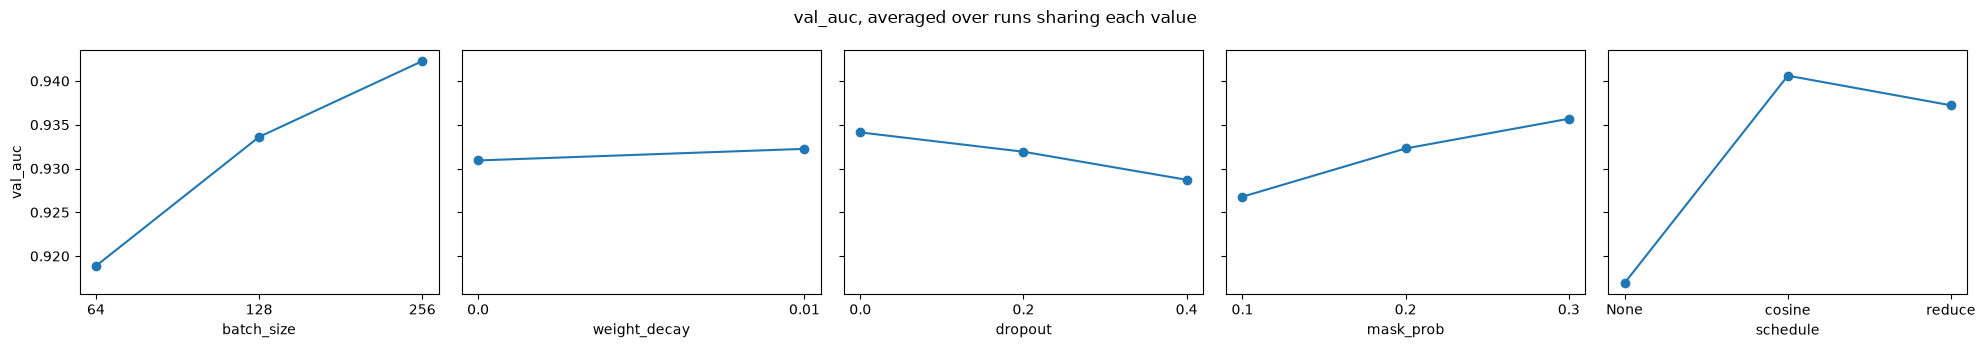

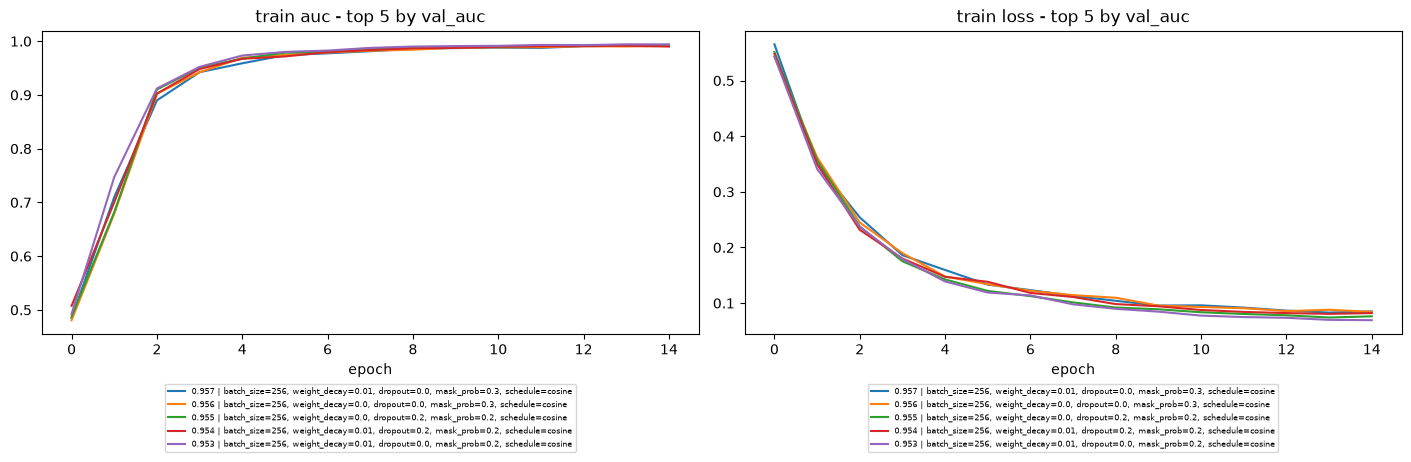

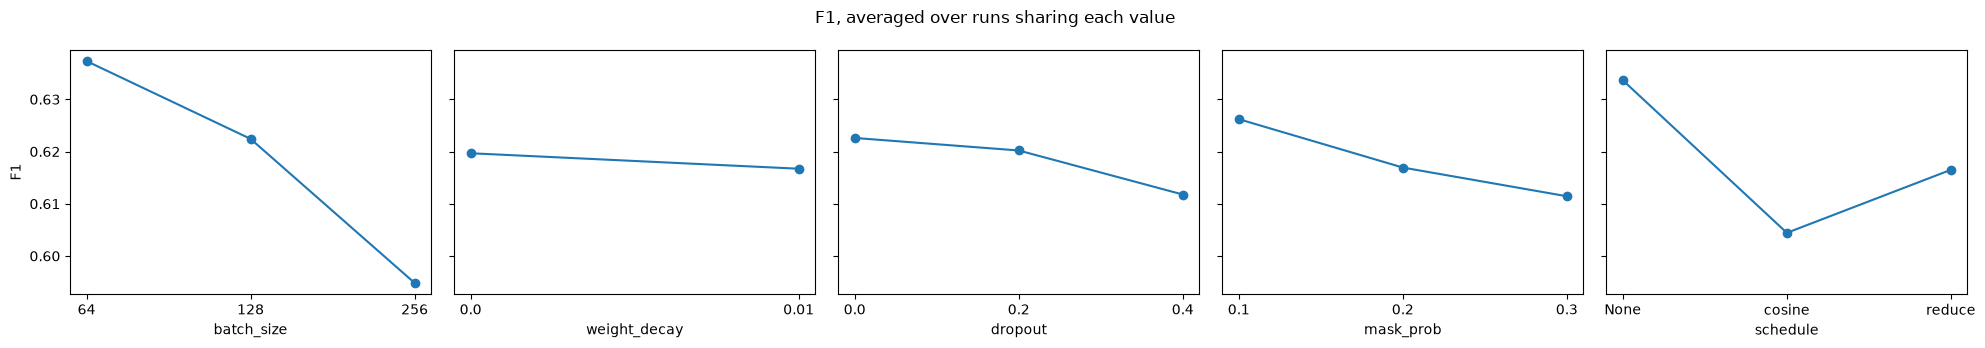

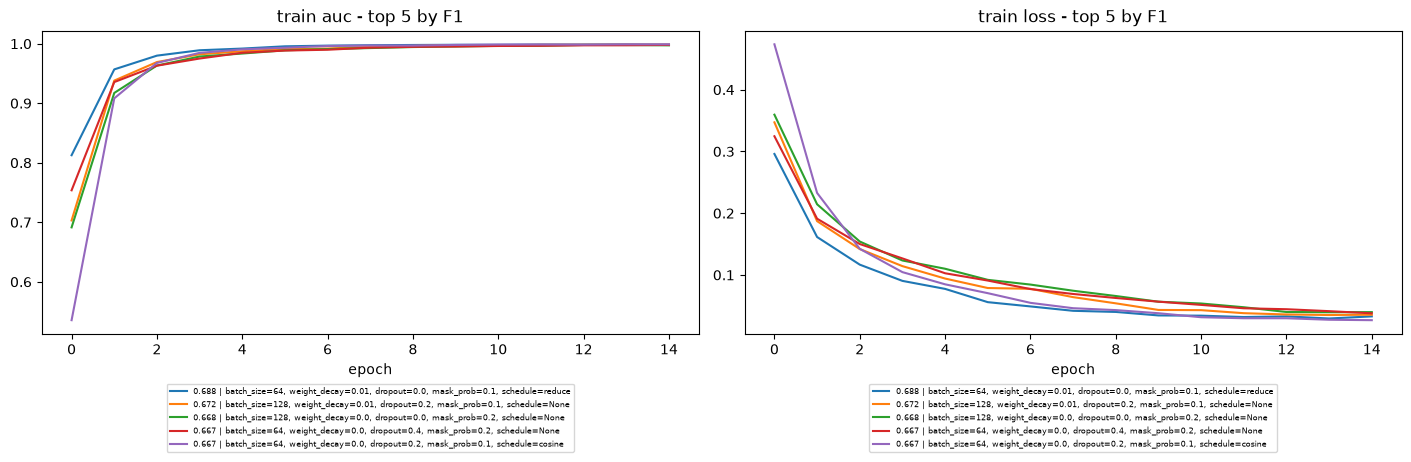

In [14]:
plot_sweep(configs, results, metric="val_auc")
plot_sweep(configs, results, metric="F1")


##### Final training

Epoch 1/2


/home/danie/codice/uni/nlp-project/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 125ms/step - auc: 0.5139 - loss: 0.4236 - val_auc: 0.7655 - val_loss: 0.3961
Epoch 2/2
62/62 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - auc: 0.7663 - loss: 0.3250 - val_auc: 0.8599 - val_loss: 0.2952
test loss: 0.2165 | test AUC: 0.9262
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


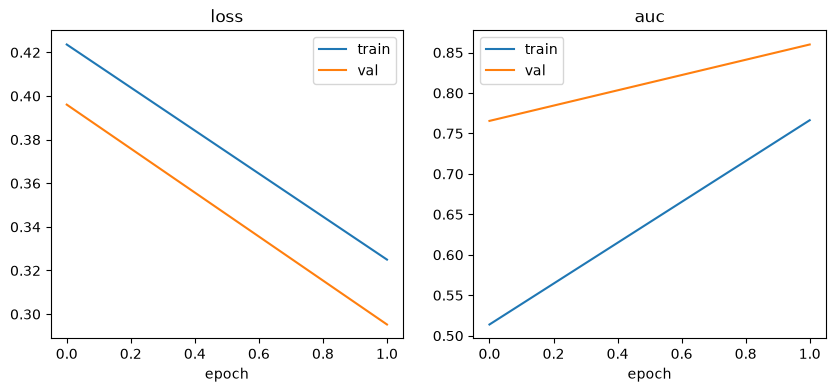

test loss: 0.2165 | test AUC: 0.9262


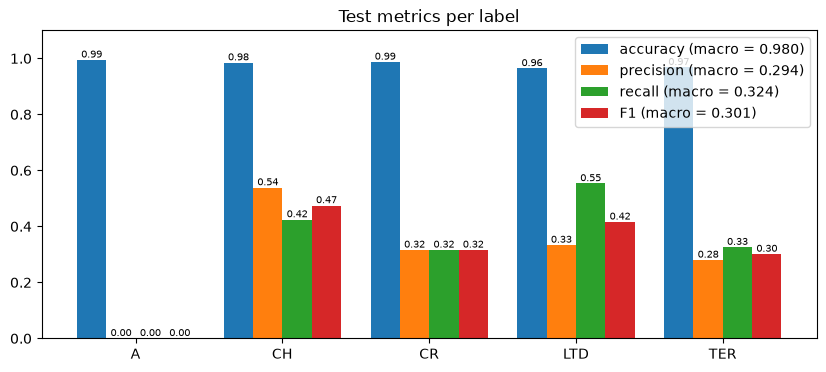

In [ ]:
final_config = LstmConfig(
    dropout=0.6,
    batch_size=256,
    sequence_len=100,
    epochs=2,
    lr=1e-3,
    weight_decay=1e0,
    mask_prob=0.2,
    loss=weighted_loss,
)
x_te, y_te = to_xy(test, word2idx, final_config.sequence_len)

model, history = train_lstm(final_config)
metrics = test_metrics(model, x_te, y_te)
plot_lstm_results(history, metrics)


# [Task 6 - 0.5 points] Transformers

In this section, you will use a transformer model pre-trained on legal text, namely
[LEGAL-BERT](https://huggingface.co/nlpaueb/legal-bert-base-uncased).

### Instructions
- **Load the Tokenizer and Model**

- **Preprocess the Dataset**:
   You will need to preprocess your dataset to prepare it for input into the model. Tokenize your text data using the
   appropriate tokenizer and ensure it is formatted correctly. Labels must be a `float` vector of size 5.

- **Train the Model**:
   Use the `Trainer` to train the model on your training data.

- **Evaluate the Model on the Test Set** using the same metrics used for LSTM-based models.

In [ ]:
MAX_LEN = 100
MODEL = "nlpaueb/legal-bert-base-uncased"


tokenizer = AutoTokenizer.from_pretrained(MODEL)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL,
    num_labels=len(LABELS),
    problem_type="multi_label_classification",  # BCEWithLogits
)


class ClauseDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame):
        self.enc = tokenizer(df["text"].tolist(), truncation=True, max_length=MAX_LEN)
        self.labels = df[LABELS].values.astype("float32")  # float vector of size 5

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def compute_metrics(eval_pred):
    logits, y = eval_pred
    prob = sigmoid(logits)
    return {
        "auc": roc_auc_score(y, prob, average="macro"),
        "f1_macro": float(np.mean(per_label_metrics(y.astype(int), prob)["F1"])),
    }


def bert_test_metrics(trainer, test_ds):
    out = trainer.predict(test_ds, metric_key_prefix="test")
    prob, y = sigmoid(out.predictions), out.label_ids.astype(int)
    metrics = {"loss": out.metrics["test_loss"], "auc": out.metrics["test_auc"], **per_label_metrics(y, prob)}
    print(f"test loss: {metrics['loss']:.4f} | test AUC: {metrics['auc']:.4f}")
    return metrics


[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 22723.14it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: nlpaueb/legal-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias            

In [ ]:
bert_train_ds = ClauseDataset(train)
bert_val_ds = ClauseDataset(validation)
bert_test_ds = ClauseDataset(test)

args = TrainingArguments(
    output_dir="legalbert_out",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    logging_strategy="epoch",  # logs the mean train loss once per epoch, for the plots
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    report_to="none",
)
trainer = Trainer(
    model=bert_model,
    args=args,
    train_dataset=bert_train_ds,
    eval_dataset=bert_val_ds,
    processing_class=tokenizer,  # use `tokenizer=` on transformers < 4.46
    compute_metrics=compute_metrics,
)

trainer.train()


Epoch,Training Loss,Validation Loss,Auc,F1 Macro
1,0.043307,0.041730,0.957633,0.546533
2,0.023209,0.041147,0.971977,0.628419
3,0.014791,0.044361,0.962842,0.642174
4,0.008768,0.045563,0.962441,0.622219
5,0.004969,0.047449,0.960240,0.617033


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.52it/s]


TrainOutput(global_step=4950, training_loss=0.019008748892581823, metrics={'train_runtime': 1714.511, 'train_samples_per_second': 46.185, 'train_steps_per_second': 2.887, 'total_flos': 3635308605331350.0, 'train_loss': 0.019008748892581823, 'epoch': 5.0})

test loss: 0.0274 | test AUC: 0.9786


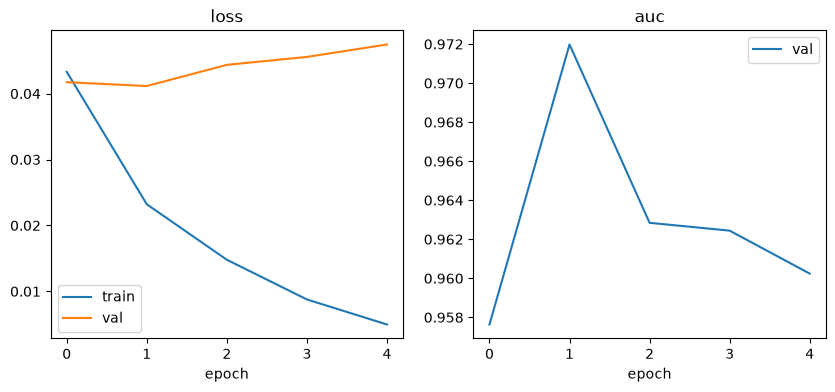

test loss: 0.0274 | test AUC: 0.9786


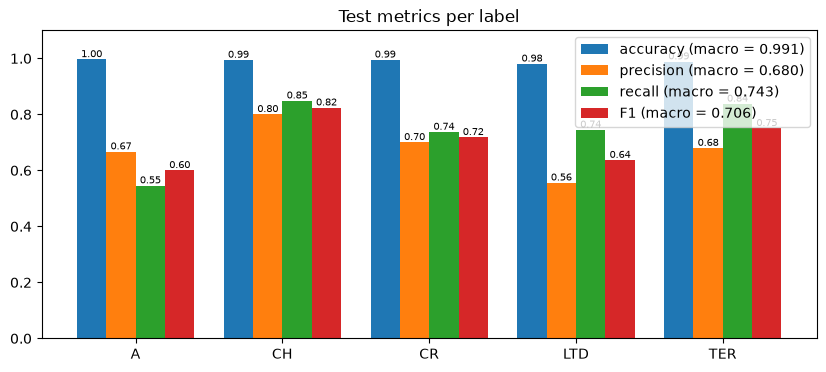

In [11]:
logs = trainer.state.log_history
bert_history = SimpleNamespace(history={  # same layout as a Keras History
    "loss": [l["loss"] for l in logs if "loss" in l],
    "val_loss": [l["eval_loss"] for l in logs if "eval_loss" in l],
    "val_auc": [l["eval_auc"] for l in logs if "eval_auc" in l],
})
bert_metrics = bert_test_metrics(trainer, bert_test_ds)
plot_lstm_results(bert_history, bert_metrics)


# [Task 7 - 1.0 points] Error Analysis

**For this task, the use of AI is prohibited. Any use constitutes a violation of academic integrity.**

After evaluating the model, perform a brief error analysis on the **test set**:

### Instructions

 - Review the results and identify common errors.

 - Summarize your findings regarding the errors and their impact on performance (e.g. but not limited to
   Out-of-Vocabulary (OOV) words, class imbalance, confusion between related categories such as `CR` and `TER`, clauses
   carrying multiple labels, and performance differences between the custom model and the transformer...)

 - Suggest possible solutions to address the identified errors.

# [Task 8 - 1.0 points] Report

**For this task, the use of AI is prohibited. Any use constitutes a violation of academic integrity.**

Wrap up your experiment in a short report (up to 2 pages).

### Instructions

* Use the NLP course report template.
* Summarize each task in the report following the provided template.

### Recommendations

The report is **not a copy-paste** of graphs, tables, and command outputs.

* Summarize classification performance in Table format.
* **Do not** report command outputs or screenshots.
* Report learning curves in Figure format.
* The error analysis section should summarize your findings.

# Submission

* **Submit** your report in PDF format.
* **Submit** your python notebook.
* Make sure your notebook is **well organized**, with no temporary code, commented sections, tests, etc...
* You can upload **model weights** in a cloud repository and report the link in the report.

## Bonus Points
Bonus points are arbitrarily assigned based on significant contributions such as:
- Outstanding error analysis
- Masterclass code organization
- Suitable extensions

**Note**: bonus points are only assigned if all task points are attributed (i.e., 4/4).

**Possible Suggestions for Bonus Points:**

- **Compare against a general-domain transformer** (e.g. `bert-base-uncased`) to quantify what legal pre-training is
  worth on this task.
- **Compare imbalance strategies**: class weighting vs. resampling vs. threshold tuning, with the same architecture.

**Possible Suggestions for Bonus Points (continued):**

- **Exploit document structure**: clauses are not independent, they come from a contract with a context. Try feeding
  the neighbouring clauses.
- **Experiment with other custom architectures or models from HuggingFace**.
- **Swap GloVe for legal word embeddings**, discussed in the next slide.

#### Bonus: legal word embeddings

[Law2Vec](https://archive.org/details/Law2Vec) is a word2vec model trained on 123k legal documents (UK, EU,
Canadian, Australian, US and Japanese legislation), released in the public domain as a plain word2vec text file:

```python
# !wget https://archive.org/download/Law2Vec/Law2Vec.100d.txt
from gensim.models import KeyedVectors
law2vec = KeyedVectors.load_word2vec_format('Law2Vec.100d.txt', binary=False)
```

Report the OOV rate of both models on your vocabulary and what the swap does to your F1-score.

#### Two things to watch with Law2Vec

* Its vocabulary is smaller than GloVe's: 169k against 400k.
* It was trained with every digit replaced by `D`, so `500` is OOV unless you normalize numbers the same way.

# FAQ

Please check this frequently asked questions before contacting us

### Use of AI

You are free to use AI as a support in your solution of the assignment, except for **Error Analysis** and
**Report**.

### Group work

Does working alone or in group affect assignment scoring?

No, it is not part of the evaluation.

### Multi-label vs. multi-class

A clause can be unfair under several categories at once, and most clauses are unfair under none. Do **not** collapse
the five columns into a single categorical label, and do **not** drop the fair clauses.

### Trainable Embeddings

You are **free** to define a trainable or non-trainable Embedding layer to load the GloVe embeddings.

### Model architecture

You **should not** change the architecture of a model (i.e., its layers).

However, you are **free** to play with their hyper-parameters.

### Neural Libraries

You are **free** to use any library of your choice to implement the networks (e.g., Keras, Tensorflow, PyTorch, JAX,
etc...)

### Robust Evaluation

Each model is trained with at least 3 random seeds.

Task 5 requires you to compute the average performance over the 3 seeds and its corresponding standard deviation.

### Expected Results

The task is hard and the corpus is small in terms of positive examples.

* Recurrent baselines are expected around **40-55** macro F1-score.
* LEGAL-BERT is expected around **60-75** macro F1-score.
* Per-category scores vary a lot: `LTD` and `TER` are the easiest, `A` is the hardest (11 positive test clauses).

These are indicative ranges, not thresholds for grading: a well-analysed lower score is worth more than an unexplained
higher one.

### Threshold tuning

You may tune the decision threshold (globally or per category), but **only** on the validation set. Report the
threshold you used.

### Model Selection for Analysis

To carry out the error analysis you are **free** to either

* Pick examples or perform comparisons with an individual seed run model (e.g., Baseline seed 1337)
* Perform ensembling via, for instance, majority voting to obtain a single model.

### Error Analysis

Some topics for discussion include:
   * Precision/Recall curves.
   * Per-category confusion matrices.
   * Specific misclassified clauses.

### Dataset References

If you want to know more about the corpus and the task:

* Lippi et al., 2019. *CLAUDETTE: an Automated Detector of Potentially Unfair Clauses in Online Terms of Service*.
  Artificial Intelligence and Law.
* Ruggeri et al., 2022. *Detecting and Explaining Unfairness in Consumer Contracts through Memory Networks*.
  Artificial Intelligence and Law.

# The End

Feel free to reach out for questions/doubts!